# Notebook 06: Agricultural Knowledge Base Preparation

## Objective

Prepare a traceable agricultural knowledge base for EdoFarm AI.

This notebook will:

1. Inspect existing agricultural knowledge candidates.
2. Establish an authoritative source register.
3. Prepare a manual source-verification queue.
4. Define the approved knowledge passage schema.
5. Prepare source documents for extraction and structuring.
6. Establish approval requirements for future retrieval.

## Knowledge approval policy

Existing Q&A records are candidates, not verified agricultural knowledge.

No answer will automatically enter the approved knowledge base.

Every approved passage must have:
- A traceable source.
- A source title and URL or document reference.
- A page, section or other location reference.
- A supported agricultural claim.
- An identified crop and relevant intent.
- Geographic applicability.
- A review and approval record.

Records that have not passed verification must not be indexed for RAG.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import date

def find_project_root(start_path=Path.cwd()):
    for path in [start_path, *start_path.parents]:
        if (
            (path / "data" / "processed").is_dir()
            and (path / "notebooks").is_dir()
        ):
            return path

    raise FileNotFoundError(
        "Could not locate EdoFarm AI project root."
    )

ROOT = find_project_root()

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
METADATA_DIR = DATA_DIR / "metadata"

# Dedicated directory for original agricultural documents.
KNOWLEDGE_SOURCE_DIR = (
    RAW_DIR / "knowledge_sources"
)

# Create required directories.
for directory in [
    KNOWLEDGE_SOURCE_DIR,
    PROCESSED_DIR,
    METADATA_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("PROJECT SETUP")
print("-------------")
print("Root:", ROOT)
print("Raw knowledge sources:", KNOWLEDGE_SOURCE_DIR)
print("Processed:", PROCESSED_DIR)
print("Metadata:", METADATA_DIR)

PROJECT SETUP
-------------
Root: c:\Users\XXMUGENX\3D Objects\edofarm-ai
Raw knowledge sources: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\raw\knowledge_sources
Processed: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\processed
Metadata: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\metadata


## 1. Inspect Existing Knowledge Candidates

Notebook 02 produced a collection of agricultural knowledge
candidates.

We will inspect their structure and review metadata.

These records will remain unapproved until their answers and
agricultural claims have been checked against reliable sources.

In [2]:
KNOWLEDGE_CANDIDATES_PATH = (
    PROCESSED_DIR /
    "edofarm_knowledge_candidates.csv"
)

if not KNOWLEDGE_CANDIDATES_PATH.exists():
    raise FileNotFoundError(
        f"Knowledge candidates not found: "
        f"{KNOWLEDGE_CANDIDATES_PATH}"
    )

knowledge_candidates = pd.read_csv(
    KNOWLEDGE_CANDIDATES_PATH,
    low_memory=False
)

print("KNOWLEDGE CANDIDATE INSPECTION")
print("------------------------------")

print("Dataset shape:", knowledge_candidates.shape)
print("Columns:", list(knowledge_candidates.columns))

if "record_id" in knowledge_candidates.columns:
    print(
        "Unique record IDs:",
        knowledge_candidates["record_id"].nunique()
    )

    print(
        "Duplicate record IDs:",
        knowledge_candidates["record_id"].duplicated().sum()
    )

# Inspect important review-status fields when available.
status_columns = [
    "review_decision",
    "answer_quality",
    "agricultural_accuracy",
    "source_check_status",
    "knowledge_base_status",
    "expert_review_status",
    "primary_intent"
]

for column in status_columns:

    if column in knowledge_candidates.columns:

        print(f"\n{column.upper()} DISTRIBUTION")

        display(
            knowledge_candidates[column]
            .value_counts(dropna=False)
            .to_frame("count")
        )

print("\nSAMPLE RECORDS")

sample_columns = [
    column for column in [
        "record_id",
        "source_dataset",
        "primary_intent",
        "question",
        "answer",
        "agricultural_accuracy",
        "source_check_status",
        "knowledge_base_status"
    ]
    if column in knowledge_candidates.columns
]

display(
    knowledge_candidates[sample_columns].head(10)
)

KNOWLEDGE CANDIDATE INSPECTION
------------------------------
Dataset shape: (398, 31)
Columns: ['record_id', 'source_dataset', 'source_record_id', 'question', 'answer', 'crop', 'country', 'state_region', 'local_area', 'source_date', 'matched_intents_v3', 'relevance_status_v3', 'exact_question_duplicate_count', 'candidate_intents', 'proposed_primary_intent', 'primary_intent', 'review_decision', 'answer_quality', 'agricultural_accuracy', 'nigerian_relevance', 'review_notes', 'review_status', 'reviewer_id', 'review_date', 'expert_review_status', 'safety_flags', 'source_check_status', 'classifier_label_status', 'knowledge_base_status', 'near_duplicate_group', 'split_group_id']
Unique record IDs: 398
Duplicate record IDs: 0

REVIEW_DECISION DISTRIBUTION


,count
review_decision,
accept,231
needs_second_review,167



ANSWER_QUALITY DISTRIBUTION


,count
answer_quality,
clear_and_relevant,231
unclear_or_incomplete,141
potentially_misleading,26



AGRICULTURAL_ACCURACY DISTRIBUTION


,count
agricultural_accuracy,
not_expert_verified,398


... (6 outputs left out)


PRIMARY_INTENT DISTRIBUTION


,count
primary_intent,
fertilizer_application,72
disease_management,66
soil_management,60
pest_management,57
irrigation,57
harvesting,50
crop_cultivation,36



SAMPLE RECORDS


,record_id,source_dataset,primary_intent,question,answer,agricultural_accuracy,source_check_status,knowledge_base_status
0,AQA_00009,Agronomy QA Pairs,disease_management,which diseases can be spread by whiteflies?,The whiteflies can spread viruses such as CMD ...,not_expert_verified,source_checked,candidate_pending_source_verification
1,AQA_00027,Agronomy QA Pairs,pest_management,why is Integrated Pest Management used?,to minimize the use of pesticides and other ch...,not_expert_verified,not_checked,candidate_pending_source_verification
2,AQA_00031,Agronomy QA Pairs,harvesting,What is the best way to store harvested wheat ...,Harvested wheat should be stored carefully to ...,not_expert_verified,not_checked,candidate_pending_source_verification
3,AQA_00045,Agronomy QA Pairs,crop_cultivation,How should the soil be prepared before plantin...,the soil must be prepared by removing weeds an...,not_expert_verified,not_checked,candidate_pending_source_verification
4,AQA_00061,Agronomy QA Pairs,pest_management,how can pest and diseases be managed in maize ...,use of chemical or organic pesticides and fung...,not_expert_verified,not_checked,candidate_pending_source_verification
5,AQA_00062,Agronomy QA Pairs,harvesting,When is the ideal time to harvest maize?,Harvesting is typically done when the kernels ...,not_expert_verified,not_checked,candidate_pending_source_verification
6,AQA_00065,Agronomy QA Pairs,pest_management,"What is the fall armyworm, and why is it a con...","The fall armyworm, in particular, is a major c...",not_expert_verified,not_checked,requires_expert_review
7,AQA_00087,Agronomy QA Pairs,disease_management,What are the symptoms of cassava mosaic,"Leaves leaves become distorted and yellow, Poo...",not_expert_verified,source_checked,candidate_pending_source_verification
8,AQA_00146,Agronomy QA Pairs,harvesting,what processes are involved during harvest pha...,"harvesting the meat, fruit, vegetable or food ...",not_expert_verified,not_checked,candidate_pending_source_verification
9,AQA_00172,Agronomy QA Pairs,soil_management,List some of the soil management activites.,"soil testing, fertilization, irrigation, tilla...",not_expert_verified,not_checked,candidate_pending_source_verification


## 2. Establish the Agricultural Source Register

Create a register of potential agricultural information sources.

Source discovery and source approval are separate processes.

A source may come from an authoritative institution, but each
specific document and its agricultural claims still require review.

No source is automatically approved for retrieval.

In [3]:
source_records = [
    {
        "source_id": "SRC_NIHORT_001",
        "organisation": "National Horticultural Research Institute",
        "resource_name": "Production Manuals",
        "url": "https://nihort.gov.ng/production-manuals/",
        "source_type": "Nigerian agricultural research institute",
        "geographic_relevance": "Nigeria",
        "crop_topic_coverage": (
            "Tomato, citrus, fluted pumpkin, Corchorus, "
            "pineapple, amaranth, post-harvest handling"
        ),
        "source_identity_status": "official_institute_domain",
        "content_review_status": "pending_document_review",
        "retrieval_approval_status": "not_approved",
        "source_notes": (
            "Official manual directory. Review each individual "
            "manual before extracting knowledge."
        )
    },
    {
        "source_id": "SRC_NRCRI_001",
        "organisation": "National Root Crops Research Institute",
        "resource_name": "Extension Programme",
        "url": "https://nrcri.gov.ng/extension-programme/",
        "source_type": "Nigerian agricultural research institute",
        "geographic_relevance": "Nigeria",
        "crop_topic_coverage": (
            "Root and tuber crops, cassava, yam, sweetpotato"
        ),
        "source_identity_status": "official_institute_domain",
        "content_review_status": "pending_document_review",
        "retrieval_approval_status": "not_approved",
        "source_notes": (
            "Institutional extension programme and guide directory. "
            "Locate individual technical guides for content review."
        )
    },
    {
        "source_id": "SRC_NRCRI_002",
        "organisation": "National Root Crops Research Institute",
        "resource_name": "Root Crops Department",
        "url": "https://nrcri.gov.ng/root-crops-department/",
        "source_type": "Nigerian agricultural research institute",
        "geographic_relevance": "Nigeria",
        "crop_topic_coverage": (
            "Cassava, sweetpotato and minor root crops"
        ),
        "source_identity_status": "official_institute_domain",
        "content_review_status": "pending_document_review",
        "retrieval_approval_status": "not_approved",
        "source_notes": (
            "Research programme information. Individual research "
            "or extension publications must be reviewed."
        )
    },
    {
        "source_id": "SRC_ARCN_001",
        "organisation": "Agricultural Research Council of Nigeria",
        "resource_name": "Resources and Downloads",
        "url": "https://arcn.gov.ng/downloads",
        "source_type": "Nigerian agricultural research council",
        "geographic_relevance": "Nigeria",
        "crop_topic_coverage": (
            "Agricultural research, technical guides and "
            "best-practice manuals"
        ),
        "source_identity_status": "official_government_domain",
        "content_review_status": "pending_document_review",
        "retrieval_approval_status": "not_approved",
        "source_notes": (
            "Research-resource discovery portal. Review each "
            "downloaded publication individually."
        )
    },
    {
        "source_id": "SRC_FAO_001",
        "organisation": "Food and Agriculture Organization",
        "resource_name": "Integrated Pest Management",
        "url": (
            "https://www.fao.org/farmer-field-schools/"
            "themes/integrated-pest-management/"
        ),
        "source_type": "International agricultural organization",
        "geographic_relevance": "International",
        "crop_topic_coverage": (
            "Integrated pest management, farmer field schools, "
            "sustainable crop protection"
        ),
        "source_identity_status": "official_international_organization",
        "content_review_status": "pending_document_review",
        "retrieval_approval_status": "not_approved",
        "source_notes": (
            "Useful for general IPM principles. Not automatically "
            "applicable to Nigerian crop-specific treatment rates."
        )
    }
]

source_register = pd.DataFrame(source_records)

SOURCE_REGISTER_PATH = (
    METADATA_DIR /
    "knowledge_source_register_v1.csv"
)

source_register.to_csv(
    SOURCE_REGISTER_PATH,
    index=False
)

print("SOURCE REGISTER CREATED")
print("-----------------------")
display(
    source_register[
        [
            "source_id",
            "organisation",
            "resource_name",
            "source_identity_status",
            "retrieval_approval_status"
        ]
    ]
)

print("\nSaved:", SOURCE_REGISTER_PATH)

SOURCE REGISTER CREATED
-----------------------


,source_id,organisation,resource_name,source_identity_status,retrieval_approval_status
0,SRC_NIHORT_001,National Horticultural Research Institute,Production Manuals,official_institute_domain,not_approved
1,SRC_NRCRI_001,National Root Crops Research Institute,Extension Programme,official_institute_domain,not_approved
2,SRC_NRCRI_002,National Root Crops Research Institute,Root Crops Department,official_institute_domain,not_approved
3,SRC_ARCN_001,Agricultural Research Council of Nigeria,Resources and Downloads,official_government_domain,not_approved
4,SRC_FAO_001,Food and Agriculture Organization,Integrated Pest Management,official_international_organization,not_approved



Saved: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\metadata\knowledge_source_register_v1.csv


In [4]:
# Make a separate review copy.
# Never overwrite the original knowledge candidates.

knowledge_review_queue = knowledge_candidates.copy()

review_fields = {
    "kb_source_review_status": "pending_source_verification",
    "kb_claim_review_status": "pending_claim_verification",
    "kb_reviewer_decision": "pending",
    "kb_source_id": "",
    "kb_source_title": "",
    "kb_source_url": "",
    "kb_page_or_section": "",
    "kb_verified_source_excerpt": "",
    "kb_reviewer_id": "",
    "kb_review_date": "",
    "kb_review_notes": "",
    "kb_approval_status": "not_approved"
}

for column, default_value in review_fields.items():

    if column not in knowledge_review_queue.columns:
        knowledge_review_queue[column] = default_value

REVIEW_QUEUE_PATH = (
    PROCESSED_DIR /
    "edofarm_knowledge_candidate_review_queue_v1.csv"
)

knowledge_review_queue.to_csv(
    REVIEW_QUEUE_PATH,
    index=False
)

# Define the structure of an approved knowledge passage.
approved_passage_columns = [
    "passage_id",
    "source_id",
    "source_title",
    "source_url",
    "source_publication_date",
    "source_access_date",
    "page_or_section",
    "crop",
    "primary_intent",
    "geographic_scope",
    "language",
    "passage_text",
    "claim_summary",
    "limitations",
    "agricultural_verification_status",
    "reviewer_id",
    "review_date",
    "approval_status",
    "version",
    "supersedes_passage_id"
]

# Create an empty template, not an approved knowledge base.
approved_passage_template = pd.DataFrame(
    columns=approved_passage_columns
)

APPROVED_PASSAGE_TEMPLATE_PATH = (
    PROCESSED_DIR /
    "approved_knowledge_passages_template_v1.csv"
)

approved_passage_template.to_csv(
    APPROVED_PASSAGE_TEMPLATE_PATH,
    index=False
)

print("KNOWLEDGE REVIEW STRUCTURES CREATED")
print("-----------------------------------")

print("Original candidates:", len(knowledge_candidates))
print("Review queue:", len(knowledge_review_queue))
print("Approved passages currently:", len(approved_passage_template))

print("\nReview queue:", REVIEW_QUEUE_PATH)
print("Approved passage template:", APPROVED_PASSAGE_TEMPLATE_PATH)

print("\nNo candidate has been automatically approved.")

KNOWLEDGE REVIEW STRUCTURES CREATED
-----------------------------------
Original candidates: 398
Review queue: 398
Approved passages currently: 0

Review queue: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\processed\edofarm_knowledge_candidate_review_queue_v1.csv
Approved passage template: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\processed\approved_knowledge_passages_template_v1.csv

No candidate has been automatically approved.


In [5]:
print("NOTEBOOK 06 INITIALIZATION SUMMARY")
print("----------------------------------")

print("Knowledge candidates:", len(knowledge_candidates))
print("Source register entries:", len(source_register))
print("Review queue:", len(knowledge_review_queue))
print("Approved knowledge passages:", len(approved_passage_template))

print("\nFILES CREATED")

for path in [
    SOURCE_REGISTER_PATH,
    REVIEW_QUEUE_PATH,
    APPROVED_PASSAGE_TEMPLATE_PATH
]:
    print(path)

NOTEBOOK 06 INITIALIZATION SUMMARY
----------------------------------
Knowledge candidates: 398
Source register entries: 5
Review queue: 398
Approved knowledge passages: 0

FILES CREATED
c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\metadata\knowledge_source_register_v1.csv
c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\processed\edofarm_knowledge_candidate_review_queue_v1.csv
c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\processed\approved_knowledge_passages_template_v1.csv


## 3. Register Individual Agricultural Publications

Create a document-level inventory for the initial agricultural
knowledge collection.

Each publication will have:
- A unique document ID.
- An institutional source ID.
- An exact document title and URL.
- Crop coverage.
- Publication metadata where available.
- Download and integrity status.
- Copyright and reuse status.
- Knowledge approval status.

A publication being downloadable does not make its content approved.

In [6]:
document_records = [
    {
        "document_id": "DOC_NIHORT_001",
        "source_id": "SRC_NIHORT_001",
        "document_title": "Tomato Production Guide 2023",
        "organisation": "NIHORT",
        "document_url": "https://nihort.gov.ng/wp-content/uploads/2025/09/Tomato-production-guide-2023.pdf",
        "local_filename": "NIHORT_tomato_production_guide_2023.pdf",
        "crop_coverage": "tomato",
        "topic_coverage": "crop_cultivation,disease_management",
        "publication_year": "2023",
        "page_count": 7
    },
    {
        "document_id": "DOC_NIHORT_002",
        "source_id": "SRC_NIHORT_001",
        "document_title": "Guide to Effective Post-harvest Handling and Processing of Tomato",
        "organisation": "NIHORT",
        "document_url": "https://nihort.gov.ng/wp-content/uploads/2025/09/Guide-to-effective-post-harvest-handling-and-processing-of-tomato.pdf",
        "local_filename": "NIHORT_tomato_postharvest_guide.pdf",
        "crop_coverage": "tomato",
        "topic_coverage": "harvesting",
        "publication_year": "not_confirmed",
        "page_count": 14
    },
    {
        "document_id": "DOC_NIHORT_003",
        "source_id": "SRC_NIHORT_001",
        "document_title": "Amaranth Production Guide",
        "organisation": "NIHORT",
        "document_url": "https://nihort.gov.ng/wp-content/uploads/2020/12/AMARANTH-PRODUCTION-GUIDE.pdf",
        "local_filename": "NIHORT_amaranth_production_guide.pdf",
        "crop_coverage": "amaranth",
        "topic_coverage": "crop_cultivation,fertilizer_application,irrigation,harvesting",
        "publication_year": "not_confirmed",
        "page_count": 4
    },
    {
        "document_id": "DOC_NIHORT_004",
        "source_id": "SRC_NIHORT_001",
        "document_title": "Fluted Pumpkin (Ugu) Production Guide",
        "organisation": "NIHORT",
        "document_url": "https://nihort.gov.ng/wp-content/uploads/2020/12/Telfairia.pdf",
        "local_filename": "NIHORT_fluted_pumpkin_production_guide.pdf",
        "crop_coverage": "fluted_pumpkin",
        "topic_coverage": "crop_cultivation",
        "publication_year": "not_confirmed",
        "page_count": 10
    },
    {
        "document_id": "DOC_IITA_001",
        "source_id": "SRC_IITA_001",
        "document_title": "Growing Cassava in Nigeria",
        "organisation": "International Institute of Tropical Agriculture",
        "document_url": "https://www.iita.org/wp-content/uploads/2016/06/Growing_cassava_in_Nigeria.pdf",
        "local_filename": "IITA_growing_cassava_in_nigeria.pdf",
        "crop_coverage": "cassava",
        "topic_coverage": "crop_cultivation,soil_management,pest_management,weed_management",
        "publication_year": "not_confirmed",
        "page_count": None
    }
]

document_register = pd.DataFrame(document_records)

# Record fields that must remain pending until individual review.
document_register["download_status"] = "pending"
document_register["sha256"] = ""
document_register["file_size_bytes"] = None
document_register["rights_status"] = "terms_and_reuse_review_pending"
document_register["document_review_status"] = "pending"
document_register["retrieval_approval_status"] = "not_approved"

# Add IITA to the institution-level source register.
SOURCE_REGISTER_PATH = (
    METADATA_DIR / "knowledge_source_register_v1.csv"
)

existing_sources = pd.read_csv(SOURCE_REGISTER_PATH)

iita_source = pd.DataFrame([{
    "source_id": "SRC_IITA_001",
    "organisation": "International Institute of Tropical Agriculture",
    "resource_name": "Growing Cassava in Nigeria",
    "url": "https://www.iita.org/wp-content/uploads/2016/06/Growing_cassava_in_Nigeria.pdf",
    "source_type": "International agricultural research institute",
    "geographic_relevance": "Nigeria",
    "crop_topic_coverage": "Cassava production",
    "source_identity_status": "institutional_research_organization",
    "content_review_status": "pending_document_review",
    "retrieval_approval_status": "not_approved",
    "source_notes": "Individual cassava production guide."
}])

updated_sources = pd.concat(
    [
        existing_sources[
            existing_sources["source_id"] != "SRC_IITA_001"
        ],
        iita_source
    ],
    ignore_index=True
)

updated_sources.to_csv(
    METADATA_DIR / "knowledge_source_register_v2.csv",
    index=False
)

DOCUMENT_REGISTER_PATH = (
    METADATA_DIR / "knowledge_document_register_v1.csv"
)

document_register.to_csv(
    DOCUMENT_REGISTER_PATH,
    index=False
)

print("DOCUMENT REGISTER CREATED")
print("--------------------------")

display(
    document_register[
        [
            "document_id",
            "document_title",
            "crop_coverage",
            "page_count",
            "retrieval_approval_status"
        ]
    ]
)

print("\nDocument register:", DOCUMENT_REGISTER_PATH)
print(
    "Updated institution register:",
    METADATA_DIR / "knowledge_source_register_v2.csv"
)

DOCUMENT REGISTER CREATED
--------------------------


,document_id,document_title,crop_coverage,page_count,retrieval_approval_status
0,DOC_NIHORT_001,Tomato Production Guide 2023,tomato,7.0,not_approved
1,DOC_NIHORT_002,Guide to Effective Post-harvest Handling and P...,tomato,14.0,not_approved
2,DOC_NIHORT_003,Amaranth Production Guide,amaranth,4.0,not_approved
3,DOC_NIHORT_004,Fluted Pumpkin (Ugu) Production Guide,fluted_pumpkin,10.0,not_approved
4,DOC_IITA_001,Growing Cassava in Nigeria,cassava,NaN,not_approved



Document register: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\metadata\knowledge_document_register_v1.csv
Updated institution register: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\metadata\knowledge_source_register_v2.csv


In [7]:
from urllib.request import Request, urlopen
from urllib.error import URLError, HTTPError
import hashlib

DOWNLOAD_DIRS = {
    "NIHORT": KNOWLEDGE_SOURCE_DIR / "NIHORT",
    "International Institute of Tropical Agriculture":
        KNOWLEDGE_SOURCE_DIR / "IITA"
}

for directory in DOWNLOAD_DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)


def calculate_sha256(content):
    return hashlib.sha256(content).hexdigest()


download_results = []

for _, document in document_register.iterrows():

    organisation = document["organisation"]
    target_dir = DOWNLOAD_DIRS[organisation]

    output_path = (
        target_dir / document["local_filename"]
    )

    print("\nDownloading:", document["document_id"])

    result = {
        "document_id": document["document_id"],
        "download_status": "failed",
        "local_path": "",
        "sha256": "",
        "file_size_bytes": None,
        "download_error": ""
    }

    try:
        request = Request(
            document["document_url"],
            headers={
                "User-Agent": "Mozilla/5.0"
            }
        )

        with urlopen(request, timeout=90) as response:
            content = response.read()

        # Validate the actual file signature.
        if not content.startswith(b"%PDF-"):
            raise ValueError(
                "Downloaded content is not a valid PDF."
            )

        output_path.write_bytes(content)

        result.update({
            "download_status": "downloaded",
            "local_path": str(output_path),
            "sha256": calculate_sha256(content),
            "file_size_bytes": len(content)
        })

        print("Downloaded successfully.")
        print("Size:", round(len(content) / 1024, 2), "KB")

    except Exception as error:

        result["download_error"] = str(error)

        print("Download failed:", error)
        print("You can download this PDF manually using its registered URL.")

    download_results.append(result)


download_results_df = pd.DataFrame(download_results)

# Merge download results into the document register.
document_register = document_register.drop(
    columns=[
        "download_status",
        "sha256",
        "file_size_bytes"
    ],
    errors="ignore"
)

document_register = document_register.merge(
    download_results_df,
    on="document_id",
    how="left"
)

document_register.to_csv(
    DOCUMENT_REGISTER_PATH,
    index=False
)

print("\nDOWNLOAD SUMMARY")
print("----------------")

display(
    download_results_df[
        [
            "document_id",
            "download_status",
            "file_size_bytes"
        ]
    ]
)

print(
    "\nDownloaded:",
    (download_results_df["download_status"] == "downloaded").sum()
)

print(
    "Failed:",
    (download_results_df["download_status"] == "failed").sum()
)


Downloading: DOC_NIHORT_001
Downloaded successfully.
Size: 1208.88 KB

Downloading: DOC_NIHORT_002
Downloaded successfully.
Size: 1902.55 KB

Downloading: DOC_NIHORT_003
Downloaded successfully.
Size: 65.38 KB

Downloading: DOC_NIHORT_004
Downloaded successfully.
Size: 1153.35 KB

Downloading: DOC_IITA_001
Download failed: HTTP Error 404: Not Found
You can download this PDF manually using its registered URL.

DOWNLOAD SUMMARY
----------------


,document_id,download_status,file_size_bytes
0,DOC_NIHORT_001,downloaded,1237895.0
1,DOC_NIHORT_002,downloaded,1948207.0
2,DOC_NIHORT_003,downloaded,66945.0
3,DOC_NIHORT_004,downloaded,1181032.0
4,DOC_IITA_001,failed,NaN



Downloaded: 4
Failed: 1


## 5. PDF Text Extraction

Extract text from all successfully downloaded agricultural
publications.

Preserve:
- Document ID.
- Source title and URL.
- Physical PDF page number.
- Extracted page text.
- Character count.
- Extraction status.

Pages with little or no extractable text will be flagged
for visual inspection.

Do not automatically approve extracted content.
Do not automatically apply OCR.

In [8]:
%pip install pymupdf

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
   ---------------------------------------- 0.0/63.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/63.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/63.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/63.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/63.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/63.0 MB 621.2 kB/s eta 0:01:41
   ---------------------------------------- 0.5/63.0 MB 621.2 kB/s eta 0:01:41
   ---------------------------------------- 0.8/63.0 MB 620.3 kB/s eta 0:01:41
    --------------------------------------- 1.0/63.0 MB 696.4 kB/s eta 0:01:29
    --------------------------------------- 1.0/63.0 MB 696.4 kB/s eta 0:01:29
    --------------------------------------- 1.3/63.0 MB 692.0 kB/s eta 0:01:30
    --------------------------------------- 1.6/63.0 MB 735.8 kB/s eta 0:01:24
    ----------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import fitz
import json
import hashlib
from pathlib import Path

INTERIM_DIR = DATA_DIR / "interim"

EXTRACTION_DIR = (
    INTERIM_DIR / "knowledge_extraction"
)

EXTRACTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

extracted_pages = []
extraction_summary = []

for _, document in document_register.iterrows():

    if document["download_status"] != "downloaded":
        print(
            "Skipping unavailable document:",
            document["document_id"]
        )
        continue

    document_id = document["document_id"]
    file_path = Path(document["local_path"])

    if not file_path.exists():
        print("Missing file:", document_id)
        continue

    print("\nExtracting:", document_id)

    try:
        pdf = fitz.open(file_path)

        total_chars = 0
        low_text_pages = 0

        for page_index, page in enumerate(pdf):

            # Physical PDF page number, starting at 1.
            page_number = page_index + 1

            page_text = page.get_text(
                "text",
                sort=True
            ).strip()

            character_count = len(page_text)
            total_chars += character_count

            if character_count < 80:
                extraction_status = "needs_visual_inspection"
                low_text_pages += 1
            else:
                extraction_status = "text_extracted"

            extracted_pages.append({
                "document_id": document_id,
                "document_title": document["document_title"],
                "source_url": document["document_url"],
                "pdf_page_number": page_number,
                "page_text": page_text,
                "character_count": character_count,
                "extraction_status": extraction_status
            })

        document_hash = hashlib.sha256(
            file_path.read_bytes()
        ).hexdigest()

        extraction_summary.append({
            "document_id": document_id,
            "document_title": document["document_title"],
            "page_count": len(pdf),
            "total_characters": total_chars,
            "low_text_pages": low_text_pages,
            "extracted_pages": len(pdf),
            "sha256": document_hash,
            "extraction_status": (
                "completed"
                if low_text_pages == 0
                else "completed_with_review_flags"
            )
        })

        print("Pages:", len(pdf))
        print("Extracted characters:", total_chars)
        print("Pages flagged:", low_text_pages)

        pdf.close()

    except Exception as error:

        print("Extraction failed:", document_id, error)

# Convert results to DataFrames.
extracted_pages_df = pd.DataFrame(extracted_pages)

extraction_summary_df = pd.DataFrame(
    extraction_summary
)

# Save page-level extraction as JSONL.
PAGE_TEXT_PATH = (
    EXTRACTION_DIR /
    "knowledge_document_pages_v1.jsonl"
)

with open(
    PAGE_TEXT_PATH,
    "w",
    encoding="utf-8"
) as file:

    for record in extracted_pages:
        file.write(
            json.dumps(
                record,
                ensure_ascii=False
            ) + "\n"
        )

# Save document-level summary.
EXTRACTION_SUMMARY_PATH = (
    EXTRACTION_DIR /
    "knowledge_extraction_summary_v1.csv"
)

extraction_summary_df.to_csv(
    EXTRACTION_SUMMARY_PATH,
    index=False
)

print("\nDOCUMENT EXTRACTION COMPLETED")
print("--------------------------------")

display(extraction_summary_df)

print("\nPage-level extraction:", PAGE_TEXT_PATH)
print("Extraction summary:", EXTRACTION_SUMMARY_PATH)

c:\Users\XXMUGENX\3D Objects\edofarm-ai\.venv\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(



Extracting: DOC_NIHORT_001
Pages: 7
Extracted characters: 0
Pages flagged: 7

Extracting: DOC_NIHORT_002
Pages: 14
Extracted characters: 0
Pages flagged: 14

Extracting: DOC_NIHORT_003
Pages: 4
Extracted characters: 6096
Pages flagged: 0

Extracting: DOC_NIHORT_004
Pages: 10
Extracted characters: 0
Pages flagged: 10
Skipping unavailable document: DOC_IITA_001

DOCUMENT EXTRACTION COMPLETED
--------------------------------


,document_id,document_title,page_count,total_characters,low_text_pages,extracted_pages,sha256,extraction_status
0,DOC_NIHORT_001,Tomato Production Guide 2023,7,0,7,7,8cf287af09aa141b7d76d20665741f135597c86b9177ce...,completed_with_review_flags
1,DOC_NIHORT_002,Guide to Effective Post-harvest Handling and P...,14,0,14,14,6b67cf2c872fe52218ec0a2fbabbcfcf69c96bd25af472...,completed_with_review_flags
2,DOC_NIHORT_003,Amaranth Production Guide,4,6096,0,4,66e89c21c30aa3a570f765f7eceb406040d04ad790eb12...,completed
3,DOC_NIHORT_004,Fluted Pumpkin (Ugu) Production Guide,10,0,10,10,c0237fb135ee8e0f5cb031d8b546c74d268ef898cb7ce4...,completed_with_review_flags



Page-level extraction: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\interim\knowledge_extraction\knowledge_document_pages_v1.jsonl
Extraction summary: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\interim\knowledge_extraction\knowledge_extraction_summary_v1.csv


## 6. Visual Inspection of Low-Text PDFs

Three documents produced zero extractable characters.

Render representative pages from each document and inspect
their visual content.

Determine whether:
- The page contains scanned text.
- The page contains embedded images.
- The page contains vector-based content.
- The page is genuinely blank or has another rendering issue.

Do not run OCR until this inspection is complete.


Tomato Production Guide 2023
PDF page: 3
Extractable characters: 0
Embedded images: 1
Vector drawings: 0
Preview saved: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\interim\knowledge_extraction\visual_previews\DOC_NIHORT_001_page_3.png


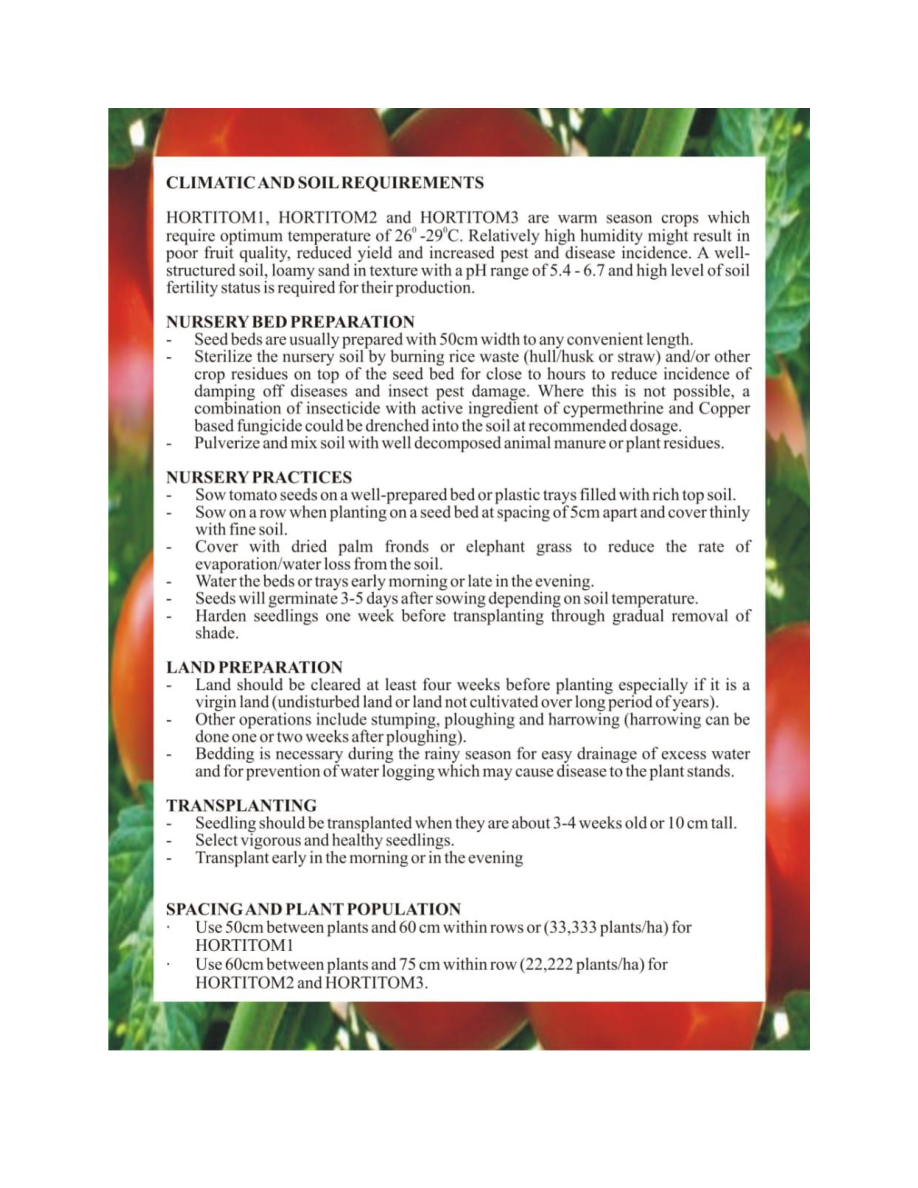


Guide to Effective Post-harvest Handling and Processing of Tomato
PDF page: 3
Extractable characters: 0
Embedded images: 1
Vector drawings: 0
Preview saved: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\interim\knowledge_extraction\visual_previews\DOC_NIHORT_002_page_3.png


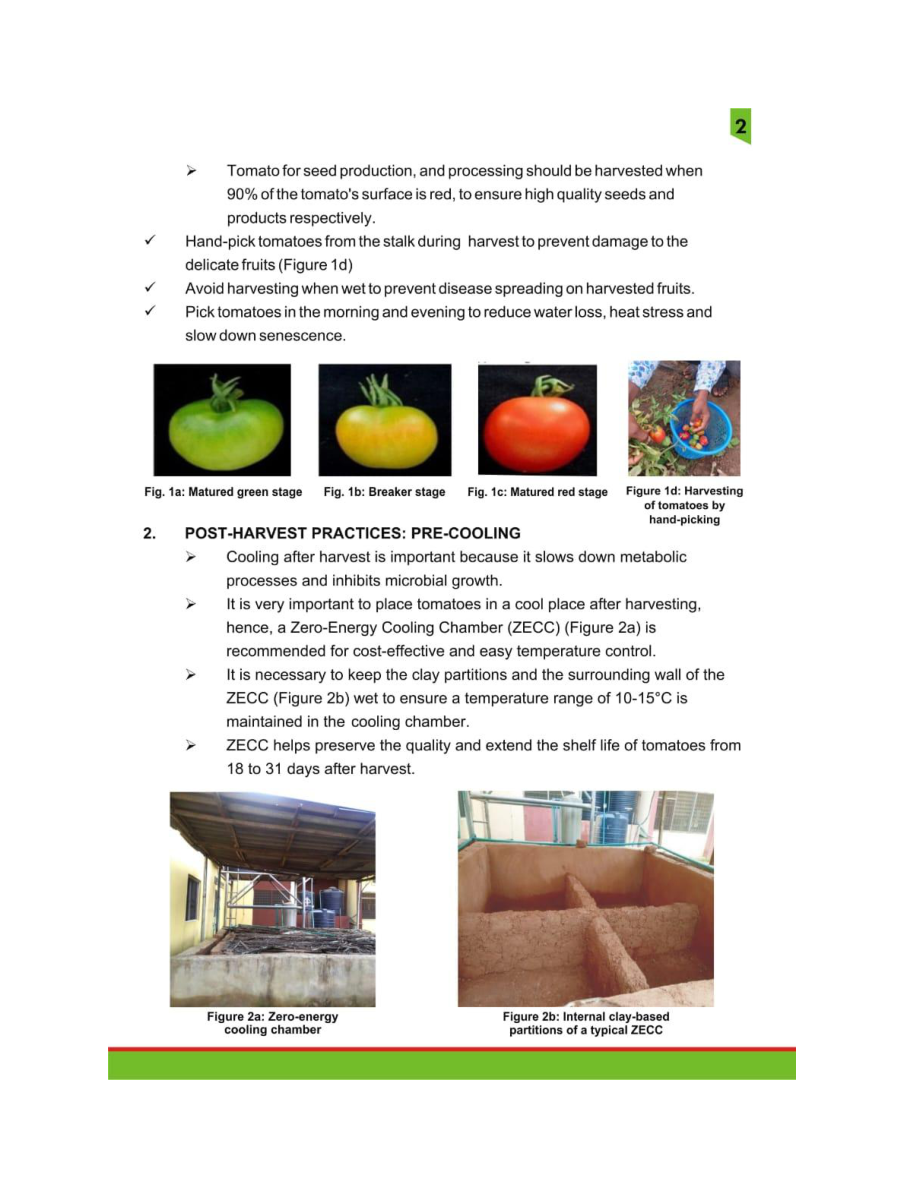


Fluted Pumpkin (Ugu) Production Guide
PDF page: 3
Extractable characters: 0
Embedded images: 1
Vector drawings: 0
Preview saved: c:\Users\XXMUGENX\3D Objects\edofarm-ai\data\interim\knowledge_extraction\visual_previews\DOC_NIHORT_004_page_3.png


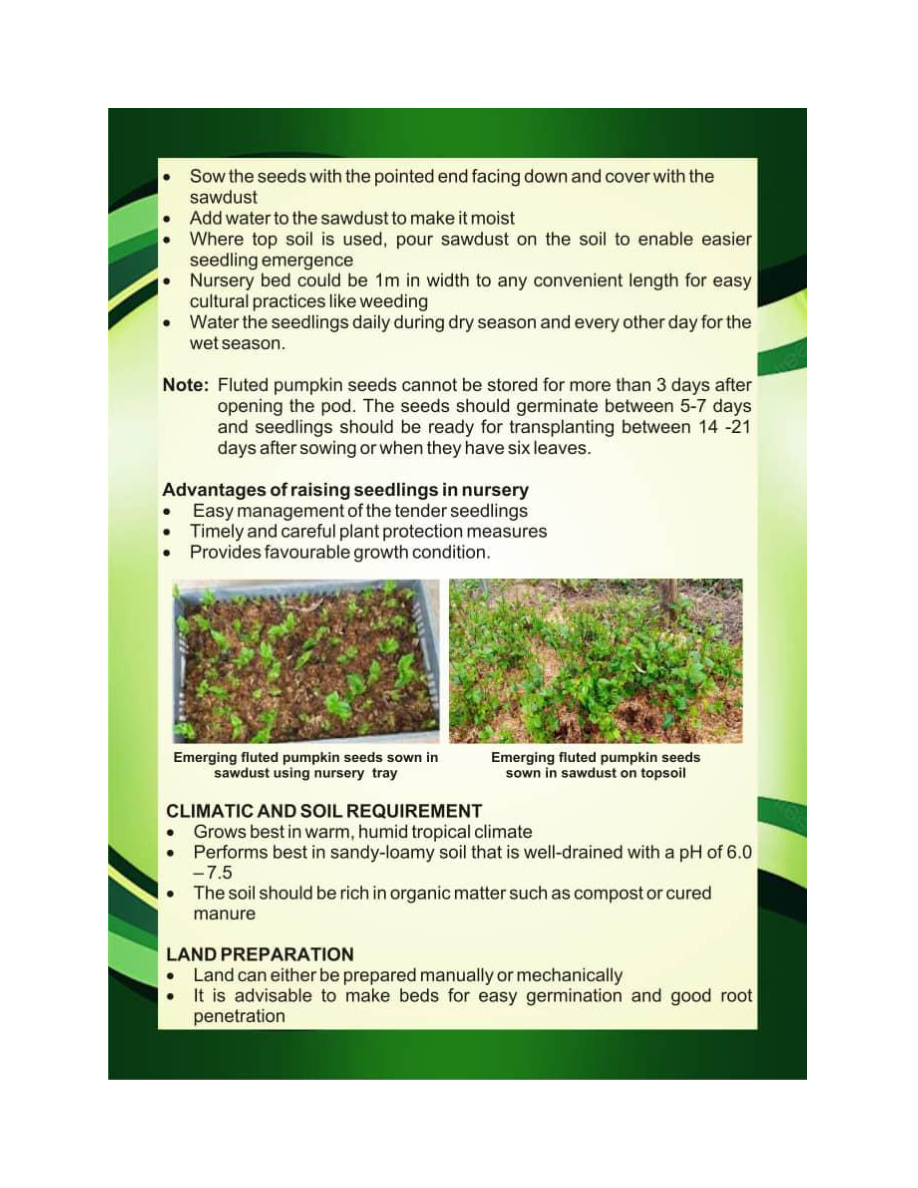

In [10]:
import pymupdf
from IPython.display import display, Image
from pathlib import Path

PREVIEW_DIR = (
    EXTRACTION_DIR / "visual_previews"
)

PREVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

documents_to_inspect = [
    "DOC_NIHORT_001",
    "DOC_NIHORT_002",
    "DOC_NIHORT_004"
]

for document_id in documents_to_inspect:

    row = document_register[
        document_register["document_id"] == document_id
    ].iloc[0]

    pdf_path = Path(row["local_path"])

    print("\n" + "=" * 60)
    print(row["document_title"])
    print("=" * 60)

    with pymupdf.open(pdf_path) as pdf:

        # Select the third page, or the last available page.
        page_index = min(2, len(pdf) - 1)

        page = pdf[page_index]

        print("PDF page:", page_index + 1)
        print("Extractable characters:", len(
            page.get_text("text").strip()
        ))
        print("Embedded images:", len(
            page.get_images(full=True)
        ))
        print("Vector drawings:", len(
            page.get_drawings()
        ))

        # Render page for visual inspection.
        pixmap = page.get_pixmap(
            matrix=pymupdf.Matrix(1.5, 1.5),
            alpha=False
        )

        preview_path = (
            PREVIEW_DIR /
            f"{document_id}_page_{page_index + 1}.png"
        )

        pixmap.save(str(preview_path))

        print("Preview saved:", preview_path)

        display(
            Image(data=pixmap.tobytes("png"))
        )

## 6. Inspect Extracted Agricultural Content

Review representative extracted pages from every document.

Check:
- Whether paragraphs are readable.
- Whether headings remain identifiable.
- Whether tables are preserved adequately.
- Whether unusual symbols or formatting errors appear.
- Whether any pages require visual inspection or OCR.

Extraction success is not equivalent to content verification.

In [ ]:
for document_id in (
    extraction_summary_df["document_id"]
):

    document_pages = extracted_pages_df[
        extracted_pages_df["document_id"] == document_id
    ].sort_values("pdf_page_number")

    print("\n" + "=" * 65)
    print(document_id)
    print("=" * 65)

    # Display up to two pages from each publication.
    for _, row in document_pages.head(2).iterrows():

        print(
            f"\nPDF PAGE {row['pdf_page_number']}"
        )

        print(
            row["page_text"][:1800]
        )

        print(
            "\nCharacter count:",
            row["character_count"]
        )

## Why Knowledge Base Retrieval and RAG Were Deferred

Knowledge-base retrieval and Retrieval-Augmented Generation (RAG) were considered as important components of the EdoFarm AI architecture.

The initial plan was to extend the response-generation pipeline:

User Question
    ↓
Intent Classification
    ↓
Knowledge Retrieval
    ↓
Gemini Flash
    ↓
Agricultural Advisory Response

The retrieval component would search approved agricultural publications and retrieve relevant information to provide Gemini with additional, source-grounded context when generating responses.

### What Was Completed

Some preliminary work was carried out towards establishing the knowledge base:

- Identified potential agricultural information sources, including NIHORT, NRCRI, ARCN and FAO resources.
- Created a knowledge-source register to document potential publications.
- Identified agricultural Q&A records that could be considered for future knowledge-base development.
- Downloaded selected agricultural production guides.
- Attempted PDF text extraction and generated page-level extraction reports.
- Identified documents requiring visual inspection or alternative extraction methods because their contents were not available as readable text.

### Why RAG Was Not Implemented

The knowledge-base component was deferred for the following reasons:

1. **Source verification:** Downloading an agricultural publication does not automatically make its contents suitable for use as verified agricultural advice. Relevant information must be checked against the original publications.

2. **Document extraction challenges:** Some downloaded NIHORT publications contained image-based pages that could not be extracted successfully using the initial text-extraction process. These documents require additional processing and visual inspection.

3. **Agricultural accuracy:** The project did not have access to a qualified agricultural expert for validating the extracted recommendations and knowledge passages.

4. **Time constraints:** Given the project deadline, priority was placed on completing the bilingual dataset, training and evaluating the intent classifier, and integrating Gemini Flash for response generation.

5. **Responsible retrieval:** Retrieved passages must be traceable to their original sources and reviewed before being used as authoritative agricultural context. Automatically inserting unverified Q&A answers into the retrieval system could introduce incorrect or misleading recommendations.

### Current Implementation Status

The current EdoFarm AI prototype uses:

- A TF-IDF word and character n-gram classifier with Logistic Regression for intent classification.
- Gemini Flash for generating English and Edo (Bini) advisory responses.
- Prompt-level instructions to communicate uncertainty and avoid unsupported agricultural recommendations.

**Knowledge-base retrieval is not active. RAG has not been implemented, and there are currently no approved agricultural knowledge passages available for retrieval.**

The preliminary document-extraction work should therefore be treated as preparation for a future knowledge-base implementation, not as an operational retrieval system.

### Future Implementation

Future development will focus on:

1. Completing the extraction of relevant agricultural publications, including image-based documents where necessary.
2. Reviewing extracted content against its original publication.
3. Having relevant agricultural information reviewed by qualified agricultural experts.
4. Dividing approved content into traceable knowledge passages.
5. Generating embeddings and indexing approved passages in a vector database.
6. Implementing semantic retrieval to identify relevant passages for incoming farmer questions.
7. Integrating retrieved passages into Gemini Flash prompts to support source-grounded responses.
8. Evaluating retrieval relevance, answer accuracy, source attribution and the system's ability to communicate when supporting information is unavailable.

### Final Decision

RAG remains a planned improvement rather than a feature of the current prototype.

This decision allows EdoFarm AI to demonstrate bilingual intent classification and AI-generated agricultural responses without presenting unverified agricultural documents or extracted answers as authoritative knowledge.

The addition of a verified agricultural knowledge base and retrieval layer is reserved for a future development phase.